In [1]:

!pip install -q pandas scikit-learn matplotlib seaborn

import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

X_data, y_data = make_classification(
    n_samples=300,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_classes=3,
    n_clusters_per_class=1,
    random_state=42
)

print("Synthetic data generated successfully!")
print("Features shape:", X_data.shape)
print("Labels shape:", y_data.shape)


Synthetic data generated successfully!
Features shape: (300, 2)
Labels shape: (300,)


In [3]:

df = pd.DataFrame(
    X_data,
    columns=["Feature_1", "Feature_2"]
)

df["Label"] = y_data

print(df.head())
print("\nDataset shape:", df.shape)


   Feature_1  Feature_2  Label
0   1.443770   0.338384      1
1  -0.973729  -1.156434      2
2  -0.808443  -1.173452      2
3  -0.988530  -0.814014      2
4  -1.001943  -1.175398      2

Dataset shape: (300, 3)


In [4]:

X = df[["Feature_1", "Feature_2"]]
y = df["Label"]

print("Input features (X):")
print(X.head())

print("\nTarget labels (y):")
print(y.head())


Input features (X):
   Feature_1  Feature_2
0   1.443770   0.338384
1  -0.973729  -1.156434
2  -0.808443  -1.173452
3  -0.988530  -0.814014
4  -1.001943  -1.175398

Target labels (y):
0    1
1    2
2    2
3    2
4    2
Name: Label, dtype: int64


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (240, 2)
X_test: (60, 2)
y_train: (240,)
y_test: (60,)


In [6]:

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [7]:

y_pred = model.predict(X_test)

print("Actual output (y_test):")
print(y_test.to_numpy())

print("\nPredicted output (y_pred):")
print(y_pred)


Actual output (y_test):
[0 0 2 2 2 0 1 0 2 0 0 2 2 1 1 2 0 2 0 0 1 0 0 1 1 0 0 1 1 1 0 1 2 0 2 1 2
 0 0 1 2 2 1 2 0 0 1 2 1 2 1 1 2 0 1 2 2 2 1 1]

Predicted output (y_pred):
[0 0 2 2 2 0 1 0 2 1 0 2 2 1 1 2 0 2 0 0 1 0 0 0 1 0 0 1 1 0 0 1 2 0 2 1 2
 0 0 1 2 2 1 2 0 0 1 2 1 2 1 1 2 0 1 2 2 2 1 1]


Confusion Matrix:
[[19  1  0]
 [ 2 18  0]
 [ 0  0 20]]
Accuracy: 0.95
Precision: 0.9507101086048454
Recall: 0.95
F1-score: 0.9499687304565353

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.95      0.93        20
           1       0.95      0.90      0.92        20
           2       1.00      1.00      1.00        20

    accuracy                           0.95        60
   macro avg       0.95      0.95      0.95        60
weighted avg       0.95      0.95      0.95        60



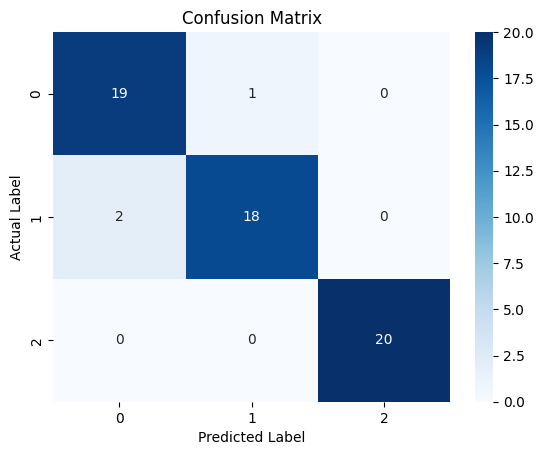

In [8]:

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Precision
print("Precision:", precision_score(
    y_test, y_pred, average="weighted", zero_division=0
))

# Recall
print("Recall:", recall_score(
    y_test, y_pred, average="weighted", zero_division=0
))

# F1-score
print("F1-score:", f1_score(
    y_test, y_pred, average="weighted", zero_division=0
))

# Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix graph
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()


In [9]:

# Save the trained model
with open("random_forest_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model saved successfully!")

# Download to your local computer
from google.colab import files
files.download("random_forest_model.pkl")


Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>